In [113]:
import numpy as np

In [7]:
import networkx as nx

file_path = "/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/PA2_10.5.graphml"  # Replace with the actual path to your GraphML file
G = nx.read_graphml(file_path)

print("Graph loaded.")
print("Number of nodes:", len(G.nodes()))
print("Number of edges:", len(G.edges()))

Graph loaded.
Number of nodes: 43438
Number of edges: 67524


In [10]:
import pandas as pd

df_partitions = pd.read_csv("/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/FMI_data/PA2_data_partitions.csv")
print(df_partitions.head())

   Index                                            Content
0      0                                            25784,4
1      1                                      26465,6,26463
2      2  26593,26594,26660,26661,26662,26663,26596,11,2...
3      3                                           27850,21
4      4                                           25,28766


In [11]:
tads = pd.read_csv('/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/FMI_data/Hi-C/PA2_domains.bed', sep='\t', header=None)
print(tads.head())

   0        1        2          3         4  5        6        7           8
0  1  4425000  4775000  ID_0.01_1 -0.640944  .  4425000  4775000  31,120,180
1  1  4775000  5225000  ID_0.01_2 -0.790786  .  4775000  5225000   51,160,44
2  1  5225000  7400000  ID_0.01_3 -0.468914  .  5225000  7400000  31,120,180
3  1  7400000  8250000  ID_0.01_4 -0.739558  .  7400000  8250000   51,160,44
4  1  8250000  9550000  ID_0.01_5 -0.868069  .  8250000  9550000  31,120,180


In [27]:
tads[0] = tads[0].astype(str)
tads[0] = 'chr' + tads[0]

In [16]:
rows_list = []
for idx, row in df_partitions.iterrows():
    # Split the 'Content' field by comma
    values = row['Content'].split(',')
    row_nodes = [] 
    for value in values:
        # Process each value (here we just print the row index and the value)
        print(f"Row {idx}: {value}")
        node = G.nodes[value]

        print("Node attributes:", node['position'])
        # Outside the inner loop, create a dataframe from the accumulated node info.
        # Move the accumulation before the inner loop, then create the dataframe after processing all values.
         # initialize list to store node data for current partition
        # (Inside the loop over values, append each node's info)
        row_nodes.append({"Chromosome": node["position"].split(":")[0], "Start": node["position"].split(":")[1].split("-")[0], "End": node["position"].split(":")[1].split("-")[1]})
        # After finishing processing all values for this partition row, create a dataframe.
    df_row = pd.DataFrame(row_nodes)
    print(f"DataFrame for partition {idx}:")
    print(df_row)
    # Append the dataframe to the list of rows
    rows_list.append(df_row)

Row 0: 25784
Node attributes: chr1:4856126-4861117
Row 0: 4
Node attributes: chr1:6214614-6214674
DataFrame for partition 0:
  Chromosome    Start      End
0       chr1  4856126  4861117
1       chr1  6214614  6214674
Row 1: 26465
Node attributes: chr1:6861480-6864621
Row 1: 6
Node attributes: chr1:6487266-6487326
Row 1: 26463
Node attributes: chr1:6859102-6859446
DataFrame for partition 1:
  Chromosome    Start      End
0       chr1  6861480  6864621
1       chr1  6487266  6487326
2       chr1  6859102  6859446
Row 2: 26593
Node attributes: chr1:7215416-7219326
Row 2: 26594
Node attributes: chr1:7219327-7221888
Row 2: 26660
Node attributes: chr1:7389676-7391483
Row 2: 26661
Node attributes: chr1:7391484-7393197
Row 2: 26662
Node attributes: chr1:7393198-7397957
Row 2: 26663
Node attributes: chr1:7397958-7401745
Row 2: 26596
Node attributes: chr1:7223297-7224579
Row 2: 11
Node attributes: chr1:9545387-9545447
Row 2: 26709
Node attributes: chr1:7541374-7545524
Row 2: 26678
Node attribut

In [17]:
import pyranges as pr

In [28]:
# Create PyRanges objects from each dataframe in rows_list
pyrange_objects = []
for df in rows_list:
    # Convert 'Start' and 'End' columns to integers
    df = df.copy()
    df['Start'] = df['Start'].astype(int)
    df['End'] = df['End'].astype(int)
    pr_obj = pr.PyRanges(df)
    pyrange_objects.append(pr_obj)

# Create a PyRanges object from the tads dataframe using columns 0, 1, and 2 as Chromosome, Start, End
tads_py = pr.PyRanges(pd.DataFrame({
    'Chromosome': tads[0].astype(str),
    'Start': tads[1].astype(int),
    'End': tads[2].astype(int)
}))

/Users/wolffjoa/opt/miniconda3/envs/ega/lib/python3.10/site-packages/pyranges/methods/init.py:45: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return {k: v for k, v in df.groupby(grpby_key)}
/Users/wolffjoa/opt/miniconda3/envs/ega/lib/python3.10/site-packages/pyranges/methods/init.py:45: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return {k: v for k, v in df.groupby(grpby_key)}
/Users/wolffjoa/opt/miniconda3/envs/ega/lib/python3.10/site-packages/pyranges/methods/init.py:45: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=Fa

In [23]:
pyrange_objects[0]

,Chromosome,Start,End
0,chr1,4856126,4861117
1,chr1,6214614,6214674


In [29]:
tads_py

,Chromosome,Start,End
0,chr1,4425000,4775000
1,chr1,4775000,5225000
2,chr1,5225000,7400000
3,chr1,7400000,8250000
4,chr1,8250000,9550000
...,...,...,...
3715,chrX,164550000,166475000
3716,chrX,166475000,166650000
3717,chrX,166650000,167250000
3718,chrX,167250000,167475000


In [39]:
# Intersect tads_py with each PyRanges object in pyrange_objects and print the results.
intersected_results = []
for pr_range in pyrange_objects:
    intersected = pr_range.join(tads_py)
    intersected_results.append(intersected)
    # print(intersected)

In [44]:
number_of_communities = len(intersected_results)

In [56]:
number_of_communities

3677

In [45]:
number_of_tads = len(tads_py)

In [57]:
number_of_tads

3720

In [41]:
intersected_results[37]

,Chromosome,Start,End,Start_b,End_b
0,chr1,57404526,57407377,57400000,57775000
1,chr1,57407378,57408238,57400000,57775000
2,chr1,57408239,57419856,57400000,57775000
3,chr1,57419857,57423895,57400000,57775000
4,chr1,57423896,57424544,57400000,57775000
5,chr1,57424545,57426140,57400000,57775000
6,chr1,57426141,57427443,57400000,57775000
7,chr1,57427444,57429881,57400000,57775000
8,chr1,58424011,58424071,57775000,59250000
9,chr1,57429882,57440028,57400000,57775000


### How many communities are from the same TAD?

In [ ]:
communities_tad_count = {}
# Loop over each intersected result (which is a PyRanges object)
for idx, pr_result in enumerate(intersected_results):
    # Get the dataframe representation of the PyRanges object
    df_int = pr_result.df
    
    # Only attempt to process if the 'Chromosome', 'Start_b', and 'End_b' columns exist
    if all(col in df_int.columns for col in ['Chromosome', 'Start_b']):
        # Count occurrences of each unique combination of Chromosome, Start_b, and End_b
        counts = df_int.groupby(['Chromosome', 'Start_b']).size()
        # Count how many unique combinations there are
        unique_count = df_int.groupby(['Chromosome', 'Start_b']).ngroups
        
        communities_tad_count[idx] = [counts, unique_count]
    else:
        print(f"Intersected result index: {idx} does not contain a 'Start_b' column.")

In [98]:
len(communities_tad_count[37][0])

3

In [99]:
communities_tad_count[37]

[Chromosome  Start_b 
 chr1        56975000     4
             57400000    16
             57775000     9
 dtype: int64,
 3]

In [80]:
communities_tad_count[37][0].iloc[1]

9

In [128]:
sum_of_counts_list = {}
percentages_list = {}
sum_of_tads_list = {}
for idx, (counts, unique_count) in communities_tad_count.items():
    
    sum_of_counts_list[idx] = (counts.sum())
    sum_of_tads_list[idx] = unique_count
    for tad, count in counts.items():
        percentages_list[idx] = (count/sum_of_counts_list[idx])
   

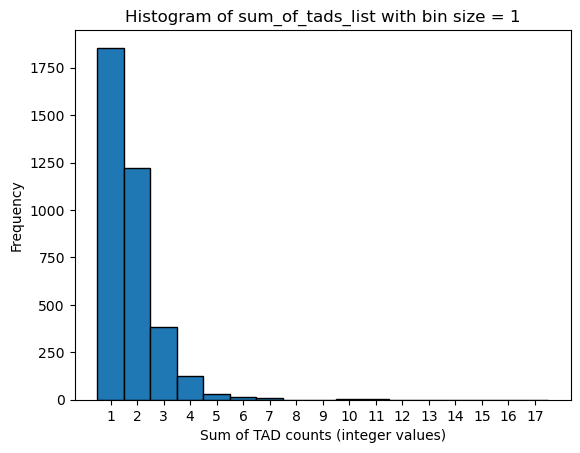

In [142]:
# Get the list of sum_of_tads values from the dictionary
values = list(sum_of_tads_list.values())

# Determine min and max integer value from the data
min_val = int(min(values))
max_val = int(max(values))

# Create bin edges so that each bin covers one integer (from min_val-0.5 to max_val+0.5)
bins_edges = np.arange(min_val - 0.5, max_val + 1, 1)

plt.hist(values, bins=bins_edges, edgecolor='black')
plt.xlabel("Sum of TAD counts (integer values)")
plt.ylabel("Frequency")
plt.title("Histogram of sum_of_tads_list with bin size = 1")
# plt.yscale('log')

# Set the x-ticks to be exactly the integer values
plt.xticks(np.arange(min_val, max_val + 1))
plt.show()

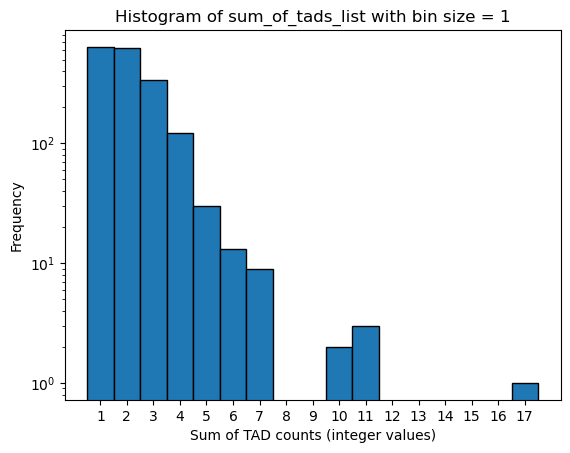

In [143]:
import numpy as np
import matplotlib.pyplot as plt

# Filter sum_of_tads_list values to include only keys where the corresponding entry in sum_of_counts_list is >= 5
filtered_values = [v for k, v in sum_of_tads_list.items() if sum_of_counts_list[k] >= 5]

# Determine min and max integer value from the data
min_val = int(min(filtered_values))
max_val = int(max(filtered_values))

# Create bin edges so that each bin covers one integer (from min_val-0.5 to max_val+0.5)
bins_edges = np.arange(min_val - 0.5, max_val + 1, 1)

plt.hist(filtered_values, bins=bins_edges, edgecolor='black')
plt.xlabel("Sum of TAD counts (integer values)")
plt.ylabel("Frequency")
plt.title("Histogram of sum_of_tads_list with bin size = 1")
plt.yscale('log')

# Set the x-ticks to be exactly the integer values
plt.xticks(np.arange(min_val, max_val + 1))
plt.show()


In [144]:
# Create a dict where keys are the number of TADs and values are lists of community ids
tads_to_community_ids = {}
for community_id, tad_count in sum_of_tads_list.items():
    tads_to_community_ids.setdefault(tad_count, []).append(community_id)

print(tads_to_community_ids)

{2: [0, 13, 14, 16, 19, 20, 21, 22, 24, 26, 27, 28, 29, 31, 36, 39, 41, 42, 43, 45, 47, 48, 49, 61, 68, 69, 74, 78, 81, 84, 86, 92, 100, 106, 107, 109, 110, 113, 114, 115, 117, 118, 128, 130, 132, 142, 147, 148, 149, 152, 153, 154, 155, 156, 158, 159, 160, 166, 168, 173, 183, 190, 191, 194, 197, 204, 206, 207, 218, 221, 224, 232, 233, 234, 237, 244, 246, 247, 250, 251, 252, 256, 257, 262, 263, 266, 277, 279, 280, 286, 287, 288, 297, 300, 304, 307, 308, 310, 313, 314, 316, 319, 326, 327, 329, 330, 331, 335, 337, 339, 345, 346, 349, 353, 354, 355, 356, 359, 360, 365, 366, 373, 378, 379, 380, 381, 383, 389, 394, 395, 397, 398, 399, 400, 403, 410, 415, 416, 417, 423, 424, 426, 429, 433, 435, 439, 442, 445, 446, 448, 453, 457, 458, 460, 461, 463, 465, 466, 469, 470, 472, 473, 475, 479, 483, 484, 488, 490, 491, 494, 495, 501, 504, 506, 510, 511, 512, 513, 515, 516, 517, 518, 519, 520, 523, 524, 525, 527, 528, 530, 531, 533, 534, 539, 546, 549, 561, 562, 563, 564, 565, 566, 571, 592, 597, 601

In [158]:
# Build a dictionary mapping each chromosome to its sorted list of TAD start positions from tads_py
df_tads = tads_py.df  # using existing tads_py
tads_by_chr = {}
for chrom, sub_df in df_tads.groupby("Chromosome"):
    tads_by_chr[chrom] = sorted(sub_df["Start"].tolist())

# Dictionaries to store neighboring info (all TADs that have at least one neighbor)
# and isolated (non-neighboring) TADs for each community id.
neighboring_communities = {}
non_neighboring_tads = {}
# New dictionary to store number of contiguous neighbor groups ("direct neighborhoods")
neighborhoods_info = {}
# New dictionary to store the actual groups of neighboring TADs
neighborhoods_detail = {}

# Helper function to compute number of contiguous groups given a list of TAD start positions
def count_neighborhoods(neighbor_list, overall):
    indices = [overall.index(x) for x in neighbor_list if x in overall]
    if not indices:
        return 0
    indices.sort()
    groups = 1
    for i in range(1, len(indices)):
        if indices[i] != indices[i-1] + 1:
            groups += 1
    return groups

# Helper function to partition neighbor TADs (by start) into contiguous groups based on overall order.
def get_neighborhoods(neighbor_list, overall):
    if not neighbor_list:
        return []
    # Create sorted list of (index, start) from overall order.
    sorted_pairs = sorted([(overall.index(x), x) for x in neighbor_list if x in overall])
    groups = []
    current_group = [sorted_pairs[0][1]]
    for i in range(1, len(sorted_pairs)):
        if sorted_pairs[i][0] == sorted_pairs[i-1][0] + 1:
            current_group.append(sorted_pairs[i][1])
        else:
            groups.append(current_group)
            current_group = [sorted_pairs[i][1]]
    groups.append(current_group)
    return groups

# Iterate over each TAD count key and its community ids.
for tad_count, comm_ids in tads_to_community_ids.items():
    for comm_id in comm_ids:
        if comm_id not in communities_tad_count:
            continue
        tad_series = communities_tad_count[comm_id][0]
        # Group community TADs per chromosome
        comm_tads = {}
        for tup in tad_series.index:
            if isinstance(tup, tuple) and len(tup) >= 2:
                chrom, start = tup[0], tup[1]
            else:
                chrom, start = tup, None
            if start is None:
                continue
            comm_tads.setdefault(chrom, []).append(start)
        
        neighbor_tads = {}
        chrom_neighborhood_groups = {}  # temporary dict to store groups per chromosome
        # Determine for each chromosome which TAD starts from comm_tads have at least one neighbor.
        for chrom, starts in comm_tads.items():
            sorted_comm = sorted(starts)
            overall = tads_by_chr.get(chrom, [])
            neighbor_set = set()
            for start in sorted_comm:
                if start in overall:
                    pos = overall.index(start)
                    if pos > 0 and overall[pos-1] in sorted_comm:
                        neighbor_set.add(start)
                        neighbor_set.add(overall[pos-1])
                    if pos < len(overall) - 1 and overall[pos+1] in sorted_comm:
                        neighbor_set.add(start)
                        neighbor_set.add(overall[pos+1])
            if neighbor_set:
                sorted_neighbors = sorted(neighbor_set)
                neighbor_tads[chrom] = sorted_neighbors
                groups = count_neighborhoods(sorted_neighbors, overall)
                neighborhoods_info.setdefault(comm_id, {})[chrom] = groups
                # Also store the actual contiguous groups
                chrom_neighborhood_groups[chrom] = get_neighborhoods(sorted_neighbors, overall)
        
        if neighbor_tads:
            neighboring_communities[comm_id] = neighbor_tads
            neighborhoods_detail[comm_id] = chrom_neighborhood_groups
            # Compute isolated (non-neighboring) TADs per chromosome as the ones not in neighbor_tads.
            isolated = {}
            for chrom, starts in comm_tads.items():
                nb = set(neighbor_tads.get(chrom, []))
                non_nb = sorted(set(starts) - nb)
                if non_nb:
                    isolated[chrom] = non_nb
            if isolated:
                non_neighboring_tads[comm_id] = isolated
        else:
            non_neighboring_tads[comm_id] = comm_tads

# Print results: communities with TADs having at least one neighbor by chromosome,
# the number of direct neighborhoods and the detailed groups.
print("Communities with TADs having at least one neighbor:")
for comm_id, neighbor_info in neighboring_communities.items():
    neigh_groups = neighborhoods_info.get(comm_id, {})
    print(f"Community {comm_id}:")
    for chrom in neighbor_info:
        print(f"  Chromosome {chrom} -> Neighboring TADs: {neighbor_info[chrom]}, "
              f"Neighborhood groups count: {neigh_groups.get(chrom, 0)}")
        detail = neighborhoods_detail.get(comm_id, {}).get(chrom, [])
        print(f"    Neighborhood groups: {detail}")

# Print results: for each community, the isolated TADs (without any neighbor)
print("\nCommunities with non-neighboring (isolated) TADs by chromosome:")
for comm_id, iso in non_neighboring_tads.items():
    print(f"Community {comm_id}: Non-neighboring TADs: {iso}")


Communities with TADs having at least one neighbor:
Community 0:
  Chromosome chr1 -> Neighboring TADs: [4775000, 5225000], Neighborhood groups count: 1
    Neighborhood groups: [[4775000, 5225000]]
Community 14:
  Chromosome chr1 -> Neighboring TADs: [31500000, 32550000], Neighborhood groups count: 1
    Neighborhood groups: [[31500000, 32550000]]
Community 16:
  Chromosome chr1 -> Neighboring TADs: [33100000, 34450000], Neighborhood groups count: 1
    Neighborhood groups: [[33100000, 34450000]]
Community 19:
  Chromosome chr1 -> Neighboring TADs: [36500000, 37250000], Neighborhood groups count: 1
    Neighborhood groups: [[36500000, 37250000]]
Community 20:
  Chromosome chr1 -> Neighboring TADs: [38975000, 39525000], Neighborhood groups count: 1
    Neighborhood groups: [[38975000, 39525000]]
Community 22:
  Chromosome chr1 -> Neighboring TADs: [38975000, 39525000], Neighborhood groups count: 1
    Neighborhood groups: [[38975000, 39525000]]
Community 24:
  Chromosome chr1 -> Neighb

/var/folders/rf/w402gy3s6j16vb5qq_5cx0wh0000gn/T/ipykernel_47298/566369237.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for chrom, sub_df in df_tads.groupby("Chromosome"):


In [153]:
neighboring_communities[1399]

{'chr7': [4425000,
  4825000,
  6650000,
  6950000,
  10825000,
  12025000,
  12600000,
  13250000,
  16275000,
  16725000,
  18625000,
  18900000,
  41225000,
  42425000]}

In [154]:
non_neighboring_tads[1399]

{'chr7': [19400000, 24025000, 44850000]}

In [155]:
communities_tad_count[1399]

[Chromosome  Start_b 
 chr7        4425000     64
             4825000     69
             6650000     36
             6950000     29
             10825000     1
             12025000    10
             12600000    72
             13250000    12
             16275000    21
             16725000    67
             18625000     8
             18900000    11
             19400000     2
             24025000     1
             41225000     2
             42425000     2
             44850000     1
 dtype: int64,
 17]

In [160]:
print("Communities with TADs having at least one neighbor:")
for comm_id, neighbor_info in neighboring_communities.items():
    neigh_groups = neighborhoods_info.get(comm_id, {})
    print(f"Community {comm_id}:")
    for chrom in neighbor_info:
        print(f"  Chromosome {chrom} -> Neighboring TADs: {neighbor_info[chrom]}, "
              f"Neighborhood groups count: {neigh_groups.get(chrom, 0)}")
        detail = neighborhoods_detail.get(comm_id, {}).get(chrom, [])
        print(f"    Neighborhood groups: {detail}")

Communities with TADs having at least one neighbor:
Community 0:
  Chromosome chr1 -> Neighboring TADs: [4775000, 5225000], Neighborhood groups count: 1
    Neighborhood groups: [[4775000, 5225000]]
Community 14:
  Chromosome chr1 -> Neighboring TADs: [31500000, 32550000], Neighborhood groups count: 1
    Neighborhood groups: [[31500000, 32550000]]
Community 16:
  Chromosome chr1 -> Neighboring TADs: [33100000, 34450000], Neighborhood groups count: 1
    Neighborhood groups: [[33100000, 34450000]]
Community 19:
  Chromosome chr1 -> Neighboring TADs: [36500000, 37250000], Neighborhood groups count: 1
    Neighborhood groups: [[36500000, 37250000]]
Community 20:
  Chromosome chr1 -> Neighboring TADs: [38975000, 39525000], Neighborhood groups count: 1
    Neighborhood groups: [[38975000, 39525000]]
Community 22:
  Chromosome chr1 -> Neighboring TADs: [38975000, 39525000], Neighborhood groups count: 1
    Neighborhood groups: [[38975000, 39525000]]
Community 24:
  Chromosome chr1 -> Neighb

### TAD community statistics

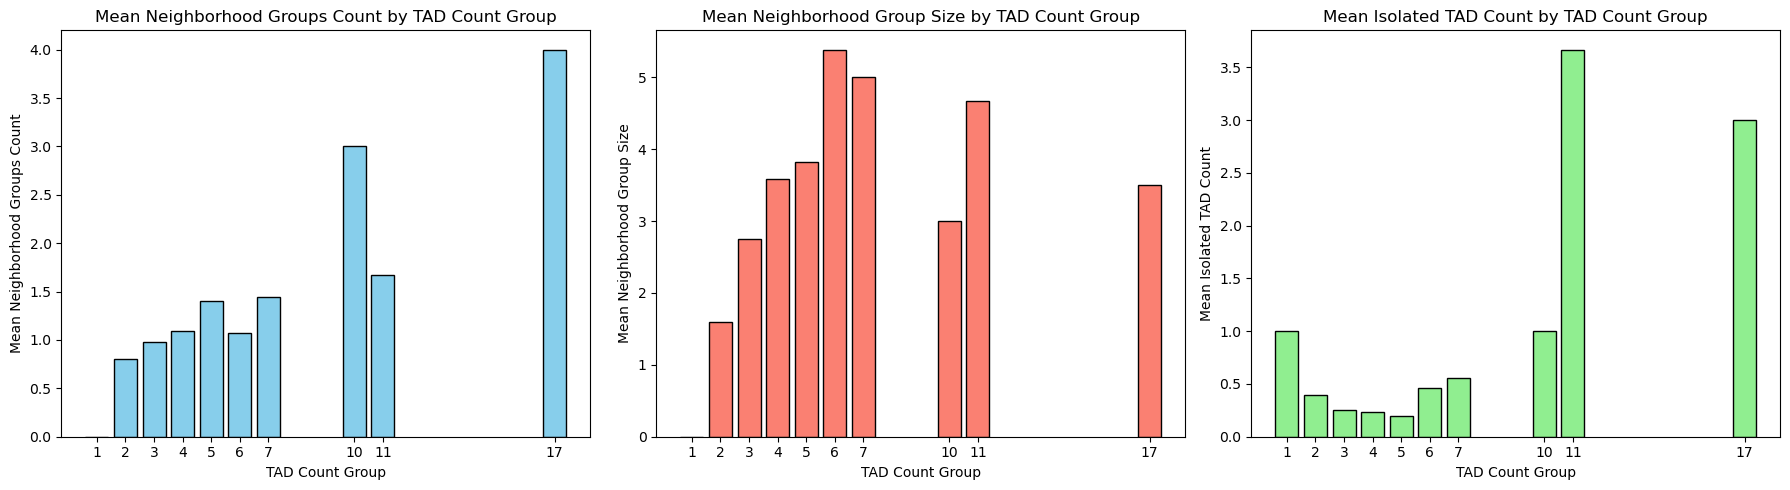

In [164]:
from statistics import mean

# Prepare dictionaries to hold per-group data.
# For each tad count (group), we store lists for neighborhood groups counts,
# mean neighborhood group sizes, and isolated TAD counts (TADs with no neighbors).
group_nbr_counts = {}
group_mean_grp_size = {}
group_isolated_counts = {}

for tad_count, comm_ids in tads_to_community_ids.items():
    nbr_counts_list = []
    mean_sizes_list = []
    isolated_counts_list = []
    for comm in comm_ids:
        # Total neighborhood groups count for this community
        tot_nbr = sum(neighborhoods_info[comm].values()) if comm in neighborhoods_info else 0
        nbr_counts_list.append(tot_nbr)
        
        # Mean neighborhood group size for this community
        grp_sizes = []
        if comm in neighborhoods_detail:
            for groups in neighborhoods_detail[comm].values():
                for grp in groups:
                    grp_sizes.append(len(grp))
        mean_sizes_list.append(mean(grp_sizes) if grp_sizes else 0)
        
        # Number of isolated TADs (with no neighbors) for this community
        if comm in non_neighboring_tads:
            isolated = sum(len(tads) for tads in non_neighboring_tads[comm].values())
        else:
            isolated = 0
        isolated_counts_list.append(isolated)
    
    group_nbr_counts[tad_count] = nbr_counts_list
    group_mean_grp_size[tad_count] = mean_sizes_list
    group_isolated_counts[tad_count] = isolated_counts_list

# For plotting, compute the overall mean per tad count group.
sorted_tad_counts = sorted(group_nbr_counts.keys())
mean_nbr_counts   = [mean(group_nbr_counts[k]) for k in sorted_tad_counts]
mean_grp_sizes    = [mean(group_mean_grp_size[k]) for k in sorted_tad_counts]
mean_isolated     = [mean(group_isolated_counts[k]) for k in sorted_tad_counts]

# Plot the three figures side-by-side.
plt.figure(figsize=(18, 5))

# (a) Mean of total neighborhood group counts per tad count group.
plt.subplot(1, 3, 1)
plt.bar(sorted_tad_counts, mean_nbr_counts, color='skyblue', edgecolor='black')
plt.xlabel("TAD Count Group")
plt.ylabel("Mean Neighborhood Groups Count")
plt.title("Mean Neighborhood Groups Count by TAD Count Group")
plt.xticks(sorted_tad_counts)

# (b) Mean of neighborhood group sizes per tad count group.
plt.subplot(1, 3, 2)
plt.bar(sorted_tad_counts, mean_grp_sizes, color='salmon', edgecolor='black')
plt.xlabel("TAD Count Group")
plt.ylabel("Mean Neighborhood Group Size")
plt.title("Mean Neighborhood Group Size by TAD Count Group")
plt.xticks(sorted_tad_counts)

# (c) Mean number of isolated TADs (with no neighbors) per tad count group.
plt.subplot(1, 3, 3)
plt.bar(sorted_tad_counts, mean_isolated, color='lightgreen', edgecolor='black')
plt.xlabel("TAD Count Group")
plt.ylabel("Mean Isolated TAD Count")
plt.title("Mean Isolated TAD Count by TAD Count Group")
plt.xticks(sorted_tad_counts)

plt.tight_layout()
plt.show()

### Which of the different TADs in a community are actually maybe wrong classified TAD borders or can be seen as sub-TADs? Which are real inter-TADs?


#### Distribution of TAD seperation score at the TAD boundary

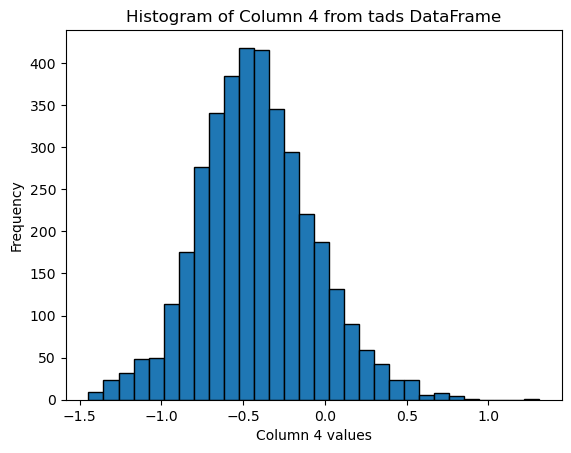

In [166]:
plt.hist(tads[4], bins=30, edgecolor='black')
plt.xlabel("Column 4 values")
plt.ylabel("Frequency")
plt.title("Histogram of Column 4 from tads DataFrame")
plt.show()

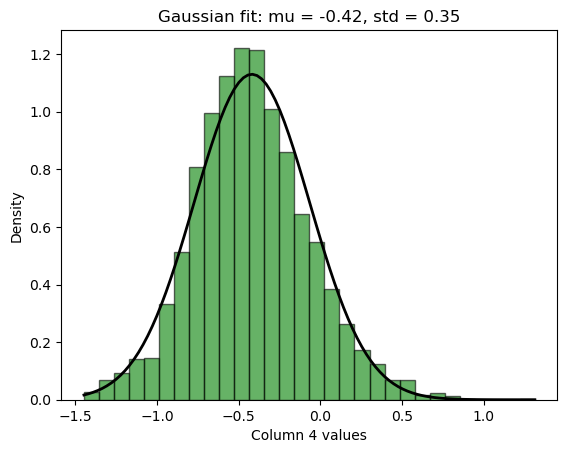

In [167]:
from scipy.stats import norm

# Fit a Gaussian distribution to tads[4]
data = tads[4]
mu, std = norm.fit(data)

# Plot histogram of the data
plt.hist(data, bins=30, density=True, edgecolor='black', alpha=0.6, color='g')

# Plot the Gaussian PDF
xmin, xmax = data.min(), data.max()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
plt.plot(x, p, 'k', linewidth=2)

plt.xlabel("Column 4 values")
plt.ylabel("Density")
plt.title(f"Gaussian fit: mu = {mu:.2f}, std = {std:.2f}")
plt.show()

In [168]:
# Compute the one-tailed p-value
value = -1.1
one_tailed_p = norm.cdf(value, loc=mu, scale=std)

# For a two-tailed p-value, double the smaller tail probability:
two_tailed_p = 2 * min(one_tailed_p, 1 - one_tailed_p)

print(f"Value: {value}")
print(f"One-tailed p-value: {one_tailed_p:.4f}")
print(f"Two-tailed p-value: {two_tailed_p:.4f}")

Value: -1.1
One-tailed p-value: 0.0269
Two-tailed p-value: 0.0539


In [171]:
# Dictionary to store p-values per community per chromosome border
tad_border_pvalues = {}

# Iterate through communities in neighboring_communities
for comm_id, chrom_dict in neighboring_communities.items():
    tad_border_pvalues[comm_id] = {}
    for chrom, borders in chrom_dict.items():
        for border in borders:
            # Find the row in tads where chromosome equals chrom and start equals border.
            score_series = tads[(tads[0] == chrom) & (tads[2] == border)][4]
            if not score_series.empty:
                score = score_series.iloc[0]
                # Compute one-tailed p-value using the norm (mu and std computed in cell 35)
                p_val = norm.cdf(score, loc=mu, scale=std)
                tad_border_pvalues[comm_id].setdefault(chrom, {})[border] = p_val

# Print the computed p-values for inspection.
print(tad_border_pvalues)

{0: {'chr1': {4775000: 0.26525181635491946, 5225000: 0.14646646455426887}}, 14: {'chr1': {31500000: 0.27350514919638014, 32550000: 0.2966837422625246}}, 16: {'chr1': {33100000: 0.5258972046993368, 34450000: 0.28572131896200176}}, 19: {'chr1': {36500000: 0.061222267388483485, 37250000: 0.4892795689048763}}, 20: {'chr1': {38975000: 0.4336404194315929, 39525000: 0.37287749971792816}}, 22: {'chr1': {38975000: 0.4336404194315929, 39525000: 0.37287749971792816}}, 24: {'chr1': {39525000: 0.37287749971792816, 40375000: 0.39087271164615234}}, 26: {'chr1': {40550000: 0.5792979438050809, 40875000: 0.9148941049741462}}, 27: {'chr1': {40550000: 0.5792979438050809, 40875000: 0.9148941049741462}}, 28: {'chr1': {40550000: 0.5792979438050809, 40875000: 0.9148941049741462}}, 29: {'chr1': {43100000: 0.5223921878511886, 43275000: 0.3928722136900398}}, 31: {'chr1': {51625000: 0.6488139428620107, 51950000: 0.48685276325722643}}, 36: {'chr1': {57400000: 0.5743607337368101, 57775000: 0.31316830080952296}}, 41

In [172]:
# Filter the tad_border_pvalues dictionary for borders with a p-value less than 0.05.
significant_pvalues = {}
for comm_id, chrom_dict in tad_border_pvalues.items():
    for chrom, border_dict in chrom_dict.items():
        for border, p_val in border_dict.items():
            if p_val < 0.05:
                significant_pvalues.setdefault(comm_id, {}).setdefault(chrom, {})[border] = p_val

print("TAD borders with p-value < 0.05:")
print(significant_pvalues)

TAD borders with p-value < 0.05:
{68: {'chr1': {87450000: 0.00425193773330831}}, 69: {'chr1': {87450000: 0.00425193773330831}}, 564: {'chr3': {16450000: 0.003750389072204993}}, 614: {'chr3': {92200000: 0.010125426587633537, 92775000: 0.029684741453683793}}, 617: {'chr3': {94625000: 0.007954360218245114}}, 622: {'chr3': {100175000: 0.011515458050819466}}, 636: {'chr3': {116000000: 0.002436207085654532}}, 716: {'chr3': {100175000: 0.011515458050819466}}, 821: {'chr4': {115700000: 0.02788925798542701}}, 876: {'chr4': {144875000: 0.01420085582176133}}, 971: {'chr4': {144875000: 0.01420085582176133}}, 1163: {'chr5': {110325000: 0.014404342483036637}}, 1232: {'chr6': {48125000: 0.032748095200026583}}, 1233: {'chr6': {48125000: 0.032748095200026583}}, 1239: {'chr6': {48125000: 0.032748095200026583}}, 1292: {'chr6': {133500000: 0.030633302851249943, 134400000: 0.02046329603698625}}, 1295: {'chr6': {134400000: 0.02046329603698625}}, 1309: {'chr6': {14600000: 0.04750399491942064}}, 1487: {'chr7'

In [174]:
import os

In [175]:
outputFolder = os.path.join("/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/", 'pyGenomeTracks', 'TAD')

In [176]:
os.makedirs(outputFolder, exist_ok=True)

In [187]:
significant_pvalues.keys()

dict_keys([68, 69, 564, 614, 617, 622, 636, 716, 821, 876, 971, 1163, 1232, 1233, 1239, 1292, 1295, 1309, 1487, 1488, 1489, 1624, 1654, 1797, 1798, 1814, 1938, 2022, 2059, 2082, 2083, 2087, 2166, 2251, 2554, 2665, 2666, 2788, 2789, 2810, 2811, 2861, 2886, 2976, 3009, 3026, 3031, 3075, 3081, 3082, 3144, 3146, 3198, 3199, 3330, 3331, 3382, 3401, 3402, 3632, 3662, 505, 711, 712, 717, 818, 880, 973, 1048, 1105, 1106, 1208, 1286, 1374, 1635, 1653, 1666, 1768, 1818, 1883, 2086, 2159, 2160, 2220, 2253, 2572, 2712, 2776, 2880, 3066, 3098, 3581, 3582, 3645, 30, 787, 1067, 1162, 1334, 1434, 1546, 1662, 1663, 1987, 2252, 2952, 320, 713, 827, 1293, 1544, 1910, 2273, 2839, 3276, 709, 1481, 2271, 2615, 3077, 3230, 2133, 2475, 1192, 1143, 1538, 1399])

In [195]:
significant_pvalues[68]

{'chr1': {87450000: 0.00425193773330831}}

In [189]:
chrom_dict

{'chr7': {12025000: 0.02456669590004495, 42425000: 0.032333118543464955}}

In [191]:
neighboring_communities[68]

{'chr1': [85500000, 87450000]}

In [ ]:
sum_of_tads_list[68]


2

In [193]:
intersected_results[68]

,Chromosome,Start,End,Start_b,End_b
0,chr1,87977929,87978347,87450000,88100000
1,chr1,87404943,87405003,85500000,87450000
2,chr1,87994167,87997644,87450000,88100000


In [203]:
# Write significant borders to a BED file
bed_rows = []
for comm_id, chrom_dict in significant_pvalues.items():
    for chrom, border_dict in chrom_dict.items():
        for border, p_val in border_dict.items():
            # Border is the end coordinate of the TAD, so subtract 1 to get the start coordinate
            start = border - 1
            end = border
            # The name can be the community ID and the p-value
            name = f"Community_{comm_id}_p_{p_val:.4f}"
            # The score can be the p-value
            score = p_val
            # Write the row to the list
            bed_rows.append([chrom, start, end, name, score])

# Create a pandas DataFrame from the list of rows
bed_df = pd.DataFrame(bed_rows)

# Define the output file path
output_bed_file = os.path.join(outputFolder, "significant_borders.bed")

# Write the DataFrame to a BED file
bed_df.to_csv(output_bed_file, sep='\t', header=False, index=False)

print(f"Significant borders written to: {output_bed_file}")

Significant borders written to: /Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/pyGenomeTracks/TAD/significant_borders.bed


In [204]:
import subprocess

# For each community in significant_pvalues, extract border positions per chromosome
regions = {}
for comm_id, chrom_dict in significant_pvalues.items():
    pr = intersected_results[comm_id]
    df_int = pr.df
    if all(col in df_int.columns for col in ['Chromosome', 'Start_b', 'End_b']):
        for chrom, sub_df in df_int.groupby('Chromosome'):
            min_border = sub_df['Start_b'].min()
            max_border = sub_df['End_b'].max()
            regions.setdefault(chrom, []).append((min_border, max_border))

print("Region boundaries extracted from significant communities:")
for chrom, region_list in regions.items():
    for region in region_list:
        print(f"{chrom}: {region}")


browser_tracks_with_hic = """
[x-axis]

[hic matrix]
file = {0}
depth = {1}
transform = log1p
file_type = hic_matrix
show_masked_bins = false
height = 4
[spacer]
height = 0.5

[TAD seperation score]
file = {2}
height = 1
type = lines
individual_color = grey
pos_score_in_bin = center
summary_color = #1f77b4
show_data_range = true
file_type = bedgraph_matrix

[vlines]
file = {3}
type = vlines

""".format('/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/FMI_data/Hi-C/GSM6505199_PA2_E10.5wt_HiC_1stBioRep_25kb.cool',
           2000000, 
           '/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/FMI_data/Hi-C/PA2_tad_score.bm',
           '/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/pyGenomeTracks/TAD/significant_borders.bed')
           
tracks_path = os.path.join(outputFolder, "browser_tracks_hic.ini")
with open(tracks_path, 'w') as fh:
    fh.write(browser_tracks_with_hic)

# For each region found (each tuple is handled individually)
for chrom, region_list in regions.items():
    for min_border, max_border in region_list:
        region_str = f"{chrom}:{min_border}-{max_border}"
        output_file = os.path.join(outputFolder, f"pygenometracks_{chrom}_{min_border}_{max_border}.pdf")
        cmd = f"pyGenomeTracks --tracks {tracks_path} --region {region_str} --outFileName {output_file} --height 20"
        print(f"Running command: {cmd}")
        subprocess.run(cmd, shell=True)


/var/folders/rf/w402gy3s6j16vb5qq_5cx0wh0000gn/T/ipykernel_47298/1117444135.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for chrom, sub_df in df_int.groupby('Chromosome'):


Region boundaries extracted from significant communities:
chr1: (85500000, 88100000)
chr1: (85500000, 88100000)
chr1: (43275000, 46125000)
chr3: (16450000, 19075000)
chr3: (92200000, 93650000)
chr3: (93650000, 95325000)
chr3: (98450000, 101300000)
chr3: (116000000, 116500000)
chr3: (100175000, 101475000)
chr3: (91825000, 93650000)
chr3: (91825000, 93650000)
chr3: (100175000, 102250000)
chr3: (94625000, 96925000)
chr3: (87700000, 95325000)
chr4: (115700000, 118400000)
chr4: (143575000, 147625000)
chr4: (143575000, 147625000)
chr4: (114275000, 115325000)
chr4: (147750000, 149975000)
chr4: (143575000, 148625000)
chr4: (60250000, 63350000)
chr4: (120375000, 123900000)
chr5: (110325000, 111400000)
chr5: (97100000, 99200000)
chr5: (136750000, 139800000)
chr5: (136750000, 139800000)
chr5: (110325000, 112425000)
chr5: (107900000, 145275000)
chr5: (138075000, 147850000)
chr5: (29350000, 139800000)
chr6: (47675000, 49925000)
chr6: (47675000, 49925000)
chr6: (48125000, 50800000)
chr6: (133500000,



INFO:pygenometracks.tracksClass:initialize 1. [x-axis]
INFO:pygenometracks.tracksClass:initialize 2. [hic matrix]

INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [TAD seperation score]
100%|██████████| 104/104 [00:00<00:00, 68976.54it/s]
INFO:pygenometracks.tracksClass:initialize 5. [vlines]
100%|██████████| 2/2 [00:00<00:00, 11169.92it/s]
INFO:pygenometracks.tracksClass:time initializing track(s):
INFO:pygenometracks.tracksClass:0.16867303848266602
DEBUG:pygenometracks.tracksClass:Figure size in cm is 40 x 20.0. Dpi is set to 72

INFO:pygenometracks.tracksClass:plotting 1. [x-axis]
INFO:pygenometracks.tracksClass:plotting 2. [hic matrix]
INFO:pygenometracks.tracks.GenomeTrack:setting min, max values for track 2. [hic matrix] to: 1.0, 178.0

INFO:pygenometracks.tracksClass:plotting 3. [spacer]
INFO:pygenometracks.tracksClass:plotting 4. [TAD seperation score]


Running command: pyGenomeTracks --tracks /Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/pyGenomeTracks/TAD/browser_tracks_hic.ini --region chr1:85500000-88100000 --outFileName /Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/pyGenomeTracks/TAD/pygenometracks_chr1_85500000_88100000.pdf --height 20




INFO:pygenometracks.tracksClass:initialize 1. [x-axis]
INFO:pygenometracks.tracksClass:initialize 2. [hic matrix]

INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [TAD seperation score]
100%|██████████| 104/104 [00:00<00:00, 74859.72it/s]
INFO:pygenometracks.tracksClass:initialize 5. [vlines]
100%|██████████| 2/2 [00:00<00:00, 12748.64it/s]
INFO:pygenometracks.tracksClass:time initializing track(s):
INFO:pygenometracks.tracksClass:0.13987994194030762
DEBUG:pygenometracks.tracksClass:Figure size in cm is 40 x 20.0. Dpi is set to 72

INFO:pygenometracks.tracksClass:plotting 1. [x-axis]
INFO:pygenometracks.tracksClass:plotting 2. [hic matrix]
INFO:pygenometracks.tracks.GenomeTrack:setting min, max values for track 2. [hic matrix] to: 1.0, 178.0

INFO:pygenometracks.tracksClass:plotting 3. [spacer]
INFO:pygenometracks.tracksClass:plotting 4. [TAD seperation score]


...



INFO:pygenometracks.tracksClass:initialize 1. [x-axis]
INFO:pygenometracks.tracksClass:initialize 2. [hic matrix]

INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [TAD seperation score]
100%|██████████| 56/56 [00:00<00:00, 65572.59it/s]
INFO:pygenometracks.tracksClass:initialize 5. [vlines]
100%|██████████| 3/3 [00:00<00:00, 14631.29it/s]
INFO:pygenometracks.tracksClass:time initializing track(s):
INFO:pygenometracks.tracksClass:0.13677096366882324
DEBUG:pygenometracks.tracksClass:Figure size in cm is 40 x 20.0. Dpi is set to 72

INFO:pygenometracks.tracksClass:plotting 1. [x-axis]
INFO:pygenometracks.tracksClass:plotting 2. [hic matrix]

INFO:pygenometracks.tracks.GenomeTrack:setting min, max values for track 2. [hic matrix] to: 1.0, 86.20000000000002

INFO:pygenometracks.tracksClass:plotting 3. [spacer]
INFO:pygenometracks.tracksClass:plotting 4. [TAD seperation score]


Running command: pyGenomeTracks --tracks /Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/pyGenomeTracks/TAD/browser_tracks_hic.ini --region chr2:90425000-91925000 --outFileName /Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/pyGenomeTracks/TAD/pygenometracks_chr2_90425000_91925000.pdf --height 20




INFO:pygenometracks.tracksClass:initialize 1. [x-axis]
INFO:pygenometracks.tracksClass:initialize 2. [hic matrix]

INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [TAD seperation score]
100%|██████████| 60/60 [00:00<00:00, 64860.37it/s]
INFO:pygenometracks.tracksClass:initialize 5. [vlines]
100%|██████████| 1/1 [00:00<00:00, 7084.97it/s]
INFO:pygenometracks.tracksClass:time initializing track(s):
INFO:pygenometracks.tracksClass:0.14327120780944824
DEBUG:pygenometracks.tracksClass:Figure size in cm is 40 x 20.0. Dpi is set to 72

INFO:pygenometracks.tracksClass:plotting 1. [x-axis]
INFO:pygenometracks.tracksClass:plotting 2. [hic matrix]

INFO:pygenometracks.tracks.GenomeTrack:setting min, max values for track 2. [hic matrix] to: 1.0, 193.20000000000002

INFO:pygenometracks.tracksClass:plotting 3. [spacer]
INFO:pygenometracks.tracksClass:plotting 4. [TAD seperation score]


Running command: pyGenomeTracks --tracks /Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/pyGenomeTracks/TAD/browser_tracks_hic.ini --region chr2:34650000-38375000 --outFileName /Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/pyGenomeTracks/TAD/pygenometracks_chr2_34650000_38375000.pdf --height 20




INFO:pygenometracks.tracksClass:initialize 1. [x-axis]
INFO:pygenometracks.tracksClass:initialize 2. [hic matrix]
INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [TAD seperation score]
100%|██████████| 149/149 [00:00<00:00, 69462.19it/s]
INFO:pygenometracks.tracksClass:initialize 5. [vlines]
100%|██████████| 2/2 [00:00<00:00, 11983.73it/s]
INFO:pygenometracks.tracksClass:time initializing track(s):
INFO:pygenometracks.tracksClass:0.14392399787902832
DEBUG:pygenometracks.tracksClass:Figure size in cm is 40 x 20.0. Dpi is set to 72

INFO:pygenometracks.tracksClass:plotting 1. [x-axis]
INFO:pygenometracks.tracksClass:plotting 2. [hic matrix]
INFO:pygenometracks.tracks.GenomeTrack:setting min, max values for track 2. [hic matrix] to: 1.0, 204.8

INFO:pygenometracks.tracksClass:plotting 3. [spacer]
INFO:pygenometracks.tracksClass:plotting 4. [TAD seperation score]
